## **Lab. 2 - Computer Vision Foundations: Images and Filtering**

<center><img src='https://miro.medium.com/max/750/1*Mu7_d3e1qPtW1e7EgsX7LQ.png' width=300px></center>
<p align="justify">



OpenCV (Open source Computer Vision - https://opencv.org/) is a famous programming library for developing real-time computer vision applications.

*   Cross-platform;
*   Free functions to be used under the open-source BSD license:
  * Pixel-level image manipulation, camera calibration, 3-D reconstruction, feature points detectors, matching algorithms, motion extraction, feature tracking;
*   Support for models developed with various deep learning frameworks (e.g., TensorFlow, PyTorch, Caffe);

OpenCV Website: (https://opencv.org/).

In [1]:
!pip install opencv-python

## **Load and visualize an image**

Lena : (512, 512, 3)
Cameraman : (256, 256, 3)
Shepp-Logan : (480, 480, 3)


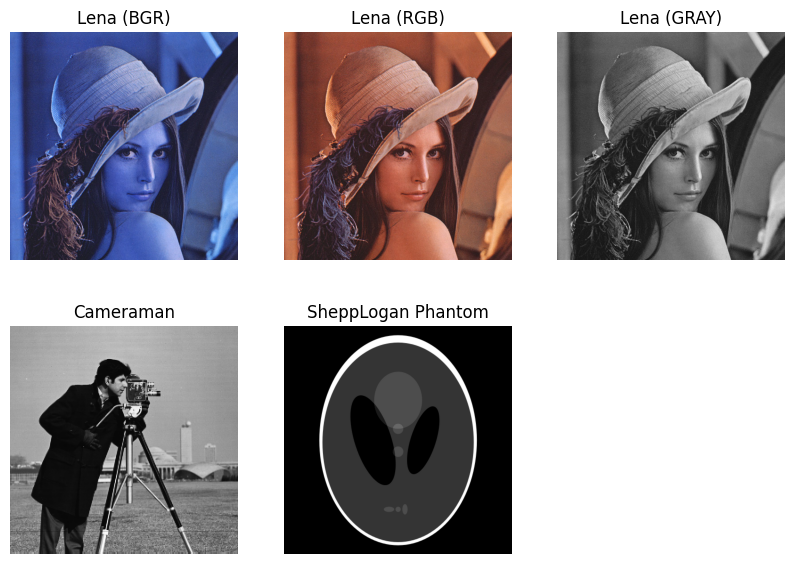

In [2]:
# Import libraries
import cv2 #OpenCV --> lecture en BGR (≠ RGB)
import matplotlib.pyplot as plt
import numpy as np

# Read images into the workspace
lena = cv2.imread('lena.bmp') # BGR image
lena_rgb = cv2.cvtColor(lena, cv2.COLOR_BGR2RGB) # RGB image
lena_gs = cv2.cvtColor(lena, cv2.COLOR_BGR2GRAY) # GS image
# lena_gs = cv2.imread('lena.bmp', cv2.IMREAD_GRAYSCALE)
#cvtColor(image,code_conversion) permet de convertir l'espace colorimétrique

cameraman = cv2.imread('cameraman.tif') #imread() lire une image
sp_phantom = cv2.imread('SheppLogan_Phantom.png')

print("Lena :", lena.shape) #avoir les dimensions de l'image (hauteur, largeur, nb valeurs par pixel)
print("Cameraman :", cameraman.shape)
print("Shepp-Logan :", sp_phantom.shape)

# Plot rgb/grayscale images
plt.figure(figsize=(10, 7))
plt.subplot(2,3,1), plt.imshow(lena), plt.title('Lena (BGR)'), plt.axis('off') #2 lignes, 3 colonnes, 1er emplacement
plt.subplot(2,3,2), plt.imshow(lena_rgb), plt.title('Lena (RGB)'), plt.axis('off')
plt.subplot(2,3,3), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.title('Lena (GRAY)'), plt.axis('off')
plt.subplot(2,3,4), plt.imshow(cameraman), plt.title('Cameraman'), plt.axis('off')
plt.subplot(2,3,5), plt.imshow(sp_phantom), plt.title('SheppLogan Phantom'), plt.axis('off')
#plt.subplot(2,3,6), plt.imshow(lena_rgb), plt.title('Lena (RGB)'), plt.axis('off')
plt.show()

In [3]:
# Print images properties
print('"Lena" image Information\n')
print("Number of Pixels: " + str(lena_rgb.size)) #size() : nombre de pixels total (512*512*3)
print("Image (RGB) shape: " + str(lena_rgb.shape)) #shape() : (hauteur,largeur,nombre de valeurs par pixel)
print("Image (GRAY) shape: " + str(lena_gs.shape))
print("Image type:  " + str(type(lena_rgb)))

# Save image shape
(height, width, channels) = lena_rgb.shape

"Lena" image Information

Number of Pixels: 786432
Image (RGB) shape: (512, 512, 3)
Image (GRAY) shape: (512, 512)
Image type:  <class 'numpy.ndarray'>


## **Image histogram**

The histogram provides a general understanding regarding the contrast, brightness, and intensity distribution of an image.

Both Matplolib and OpenCV libraries can be used to compute an image histogram.

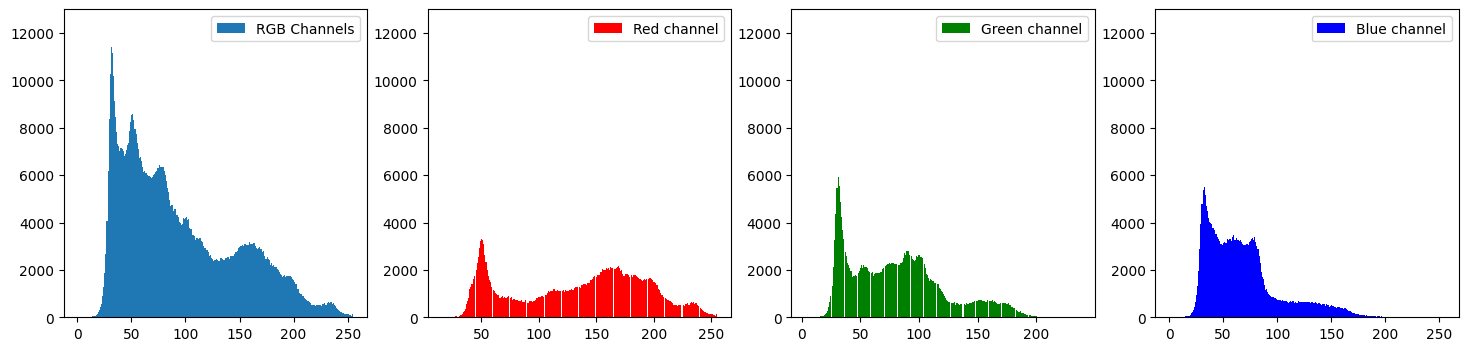

In [4]:
# Compute image histogram using matplotlib library
# Find frequency of pixels in range 0-255
plt.figure(figsize=(18,4)) #(largeur, hauteur)
plt.subplot(1,4,1), plt.ylim(0, 13000) #plt.subplot(nombre_de_lignes, nombre_de_colonnes, position)
_ = plt.hist(lena_rgb.flatten(), bins = 256) #flatten() : permet d'aplatir le tableau de tableau et bins : nb de classes utilisées pour regrouper valeurs histogramme
_ = plt.legend(['RGB Channels'])
plt.subplot(1,4,2), plt.ylim(0, 13000) #plt.ylim(valeur_minimale, valeur_maximale)
_ = plt.hist(lena_rgb[:, :, 0].flatten(), bins = 256, color = 'r') #plt.hist() : histogramme
_ = plt.legend(['Red channel'])
plt.subplot(1,4,3), plt.ylim(0, 13000)
_ = plt.hist(lena_rgb[:, :, 1].flatten(), bins = 256, color = 'g')
_ = plt.legend(['Green channel'])
plt.subplot(1,4,4), plt.ylim(0, 13000)
_ = plt.hist(lena_rgb[:, :, 2].flatten(), bins = 256, color = 'b')
_ = plt.legend(['Blue channel'])

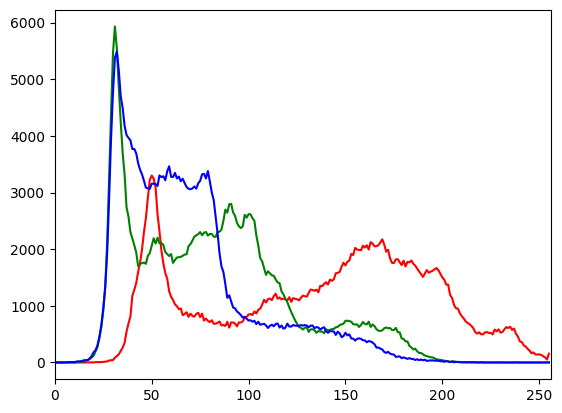

In [5]:
# Image histogram using OpenCV
# cv2.calcHist(images, channels, mask, histSize, ranges[, hist[, accumulate]]) → hist
color = ('r','g','b')
for i, col in enumerate(color):
    hist = cv2.calcHist([lena_rgb], [i], None, [256], [0,256]) #cv2.calcHist(images, channels, mask, histSize, ranges)
    plt.plot(hist, color = col)
    plt.xlim([0,256])

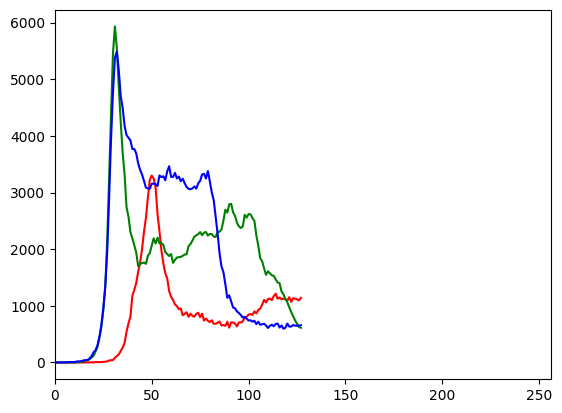

In [6]:
# Image histogram using OpenCV
# cv2.calcHist(images, channels, mask, histSize, ranges[, hist[, accumulate]]) → hist
color = ('r','g','b')
for i, col in enumerate(color):
    hist = cv2.calcHist([lena_rgb], [i], None, [128], [0,128]) #cv2.calcHist(images, channels, mask, histSize, ranges)
    plt.plot(hist, color = col)
    plt.xlim([0,256])

## **Split and Merge Image Channels**

In [7]:
#cv2.split(m[, mv]) → mv
# Warning: cv2.split() is a costly operation (in terms of time).
# So do it only if you need it. Otherwise go for Numpy indexing.
blue_ch, green_ch, red_ch = cv2.split(lena) #split() : sépare en 3 canaux BGR une image
print("Blue channel shape: " + str(blue_ch.shape))
print("Green channel shape: " + str(green_ch.shape)) #images ont 2 dimensions mtn --> (512,512)
print("Red channel shape: " + str(red_ch.shape))

Blue channel shape: (512, 512)
Green channel shape: (512, 512)
Red channel shape: (512, 512)


In [8]:
# cv2.merge(mv[, dst]) → dst
# Creates one multichannel array out of several single-channel ones.
zeros = np.zeros(blue_ch.shape, np.uint8)
lena_blue = cv2.merge((blue_ch, zeros, zeros)) #merge() : combine les 3 canaux pour refaire l'image initiale
lena_green = cv2.merge((zeros, green_ch, zeros))
lena_red = cv2.merge((zeros, zeros, red_ch))
print("lena_blue shape: " + str(lena_blue.shape))
print("lena_green shape: " + str(lena_green.shape))
print("lena_red shape: " + str(lena_red.shape))

lena_blue shape: (512, 512, 3)
lena_green shape: (512, 512, 3)
lena_red shape: (512, 512, 3)


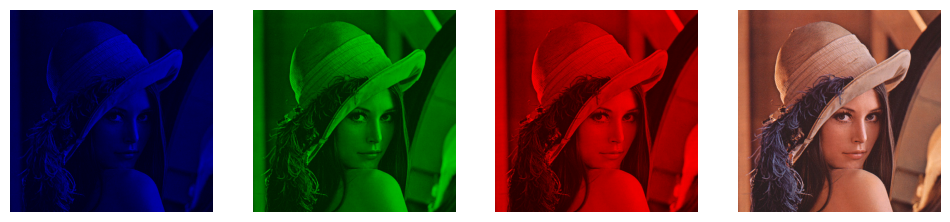

In [9]:
# Plot all images
images = [lena_blue, lena_green, lena_red, lena]
fig, ax = plt.subplots(nrows = 1, ncols = len(images), figsize = (3*len(images), 3*len(images)))
for i, p in enumerate(images):
  ax[i].imshow(cv2.cvtColor(p, cv2.COLOR_BGR2RGB))
  ax[i].axis('off')
plt.show()

## **Ex. 1 - Image Thresholding**

Image thresholding can be used to segment an image. Setting all pixel values above the threshold to a maximum value (e.g., 255) and below the threshold to zero, we get a binary image.

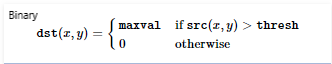

In the next exercise, you will set to zero all the pixel values below four fixed thresholds (30, 60, 90 and 120) and plot the resulting images. Use the gray scale version of Lena image. Use NumPy or OpenCV (cv2.threshold) to solve this exercise.



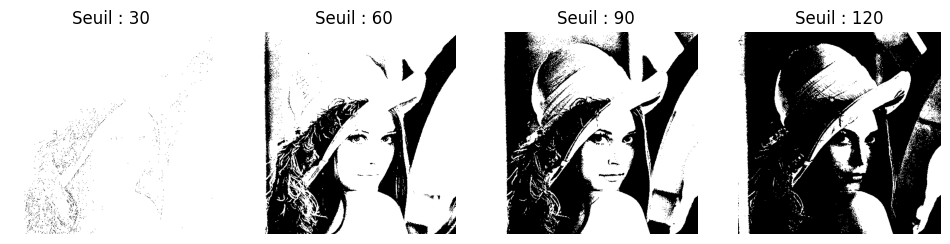

In [10]:
# Perform binary thresholding using four different values: 30, 60, 90, 120.
# As input image, use a grayscale image.

# Using Numpy

thresh = [30, 60, 90, 120]
fig, ax = plt.subplots(nrows = 1, ncols = len(thresh), figsize = (3*len(thresh), 3*len(thresh)))
""" YOUR CODE HERE """

def binary_tresholding(t):

    height,width = lena_gs.shape
    binary = np.zeros(lena_gs.shape)

    for x in range(height):
        for y in range(width):
            pixel = lena_gs[x,y]

            if pixel > t:
                binary[x,y] = 255
            else:
                binary[x,y] = 0

    return binary

for i in range(len(thresh)):
    # Appel de ta fonction pour le seuil actuel
    img_binaire = binary_tresholding(thresh[i])
    
    # Affichage dans la case ax[i]
    ax[i].imshow(img_binaire, cmap='gray')
    ax[i].set_title(f'Seuil : {thresh[i]}')
    ax[i].axis('off') # Optionnel : masque les axes numériques pour un rendu plus net

plt.show()


## **Image rotation**

In [11]:
# Rotate an input image by 90 degrees
# Firstly, you need to compute the rotation matrix and then apply it to the input image.
# cv2.getRotationMatrix2D(center, angle, scale) → retval
rotation_matrix = cv2.getRotationMatrix2D((width/2, height/2), 90, 1) #centre de rotation, angle de rotation & taille inchangée pendant la transformation
print(f"Rotation matrix (90 deg):\n{rotation_matrix}")

Rotation matrix (90 deg):
[[ 6.12323400e-17  1.00000000e+00 -2.84217094e-14]
 [-1.00000000e+00  6.12323400e-17  5.12000000e+02]]


In [12]:
# Apply an affine transformation to the input image.
# cv.WarpAffine(src, dst, mapMatrix, flags=CV_INTER_LINEAR+CV_WARP_FILL_OUTLIERS, fillval=(0, 0, 0, 0)) → None
lena_rotated = cv2.warpAffine(lena, rotation_matrix, (width, height)) # define output size

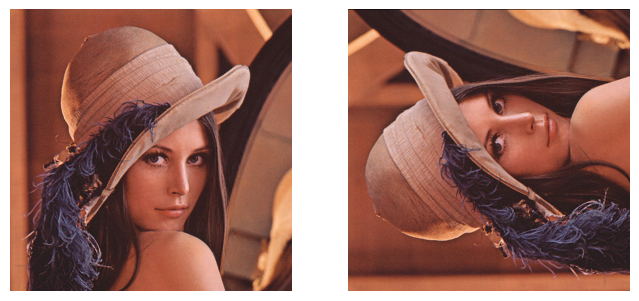

In [13]:
# Plot images
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1), plt.imshow(cv2.cvtColor(lena, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.subplot(1,2,2), plt.imshow(cv2.cvtColor(lena_rotated, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.show()

In [14]:
# Rotate by 45 degrees and set scale to 0.5
rotation_scaling_matrix = cv2.getRotationMatrix2D((width/2, height/2), 45, 0.5) #centre de rotation, angle de rotation & taille divisée par 2
lena_rotated_scaled = cv2.warpAffine(lena, rotation_scaling_matrix, (width, height))
print(f"Rotation matrix (45 deg) + scaling:\n{rotation_scaling_matrix}")

Rotation matrix (45 deg) + scaling:
[[  0.35355339   0.35355339  74.98066402]
 [ -0.35355339   0.35355339 256.        ]]


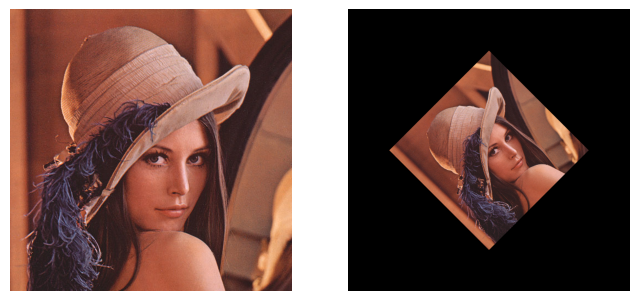

In [15]:
# Plot images
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1), plt.imshow(cv2.cvtColor(lena, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.subplot(1,2,2), plt.imshow(cv2.cvtColor(lena_rotated_scaled, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.show()

## **Image Resizing and Cropping**

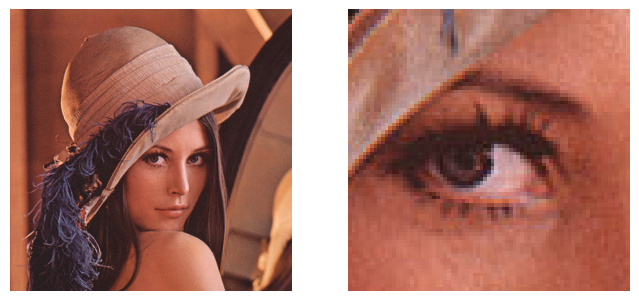

In [16]:
startRow = int(height * .45) #ligne où commence le recadrage (.45 -> 45%)
startCol = int(width  * .45) #colonne où commence le recadrage
endRow   = int(height * .60) #ligne où finit le recadrage (.60 -> 60%)
endCol   = int(width  * .60) #colonne où finit le recadrage

# Crop image
lena_cropped = lena[startRow:endRow, startCol:endCol] #image[ligne, colonnes]

# Plot images
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1), plt.imshow(cv2.cvtColor(lena, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.subplot(1,2,2), plt.imshow(cv2.cvtColor(lena_cropped, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.show()

In [17]:
# Image resizing
# cv2.resize(src, dsize[, dst[, fx[, fy[, interpolation]]]]) → dst
lena_resized = cv2.resize(lena, (300, 200)) # (width, height)
print("Original image (shape): " + str(lena.shape))
print("Scaled image (shape):  " + str(lena_resized.shape))

Original image (shape): (512, 512, 3)
Scaled image (shape):  (200, 300, 3)


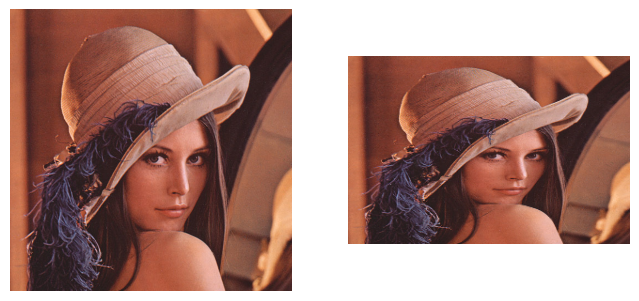

In [18]:
# Plot images
plt.figure(figsize=(8, 5))
plt.subplot(1,2,1), plt.imshow(cv2.cvtColor(lena, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.subplot(1,2,2), plt.imshow(cv2.cvtColor(lena_resized, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.show()

# **2-D Convolution**
2-D convolution can be used to apply smoothing, sharpening or edge detection filters to images. The output image is produced by sliding a kernel (filter) over the input image.

# **Ex. 2 - Box Blur (box linear filter)**

In this exercise, you will implement two functions for applying a box filter to an input image using the NumPy library. Firstly, you will define a function to create a $k x k$ blur filter. Then, a function to perform the 2-D convolution operator. Consider a grayscale input image, stride equals to 1 to obtain a blurred image as output. Input and output images should have the same spatial size.

**Tip**: Use zero-padding to get the same spatial size for both input and output images. **The padding size should be set to $\frac{k-1}{2}$, where $k$ is the kernel size.**


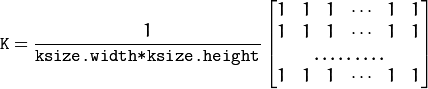

In [19]:
def box_filter(kernel_size):
  '''
  Create a k x k box filter.

  Input parameters
  ----------------
  kernel_size: int # size of the squared kernel

  Output parameters
  ----------------
  Filter: np.array [k x k] # box filter

  To check
  ------------
  kernel size must be an odd number (hint: use "assert")
  '''

  assert kernel_size % 2 == 1, "The kernel_size number should be odd"

  num = kernel_size * kernel_size
  box_filter = np.full((kernel_size,kernel_size),1/num)
  return box_filter

tmp = box_filter(3)
print(tmp)
print(type(tmp))

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
<class 'numpy.ndarray'>


[[38.840237 44.366863 49.946747 ... 36.266273 32.384617 28.260355]
 [44.349113 50.64497  56.988167 ... 41.467457 37.005917 32.295856]
 [49.816566 56.881657 63.988167 ... 46.485207 41.449703 36.159763]
 ...
 [45.213017 52.54438  59.76923  ... 22.568047 20.177515 17.71006 ]
 [40.142014 46.662724 53.04142  ... 20.071007 17.970415 15.792899]
 [35.053253 40.76923  46.307693 ... 17.591717 15.775148 13.87574 ]]


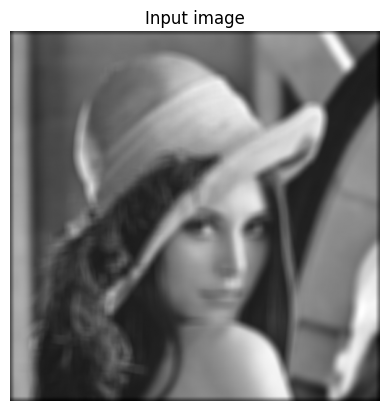

In [20]:
def conv_2d(image, kernel):
  '''
  Apply a k x k filter to the input image.

  Input parameters
  ----------------
  image: np.array # input image
  kernel: np.array [k x k] # filter to apply (box_filter(kernel_size))

  Output parameters
  ----------------
  Image: np.array

  To check
  ------------
  Grayscale image is required
  '''

  # check grayscale image
  assert image.ndim == 2, "Grayscale image is required" #ndim = nombre de dimensions de l'image
  # convert image data type to float32 (to compare our result with opencv)
  image = image.astype(np.float32) #conversion en float32

  # add padding to the original image
  kernel_size = len(kernel[0]) #taille du kernel
  padding_size = int((kernel_size - 1) / 2) #(k-1)/2

  image_pad = np.pad(image,pad_width=padding_size) #on ajoute du padding à l'image

  # prepare the empty output image
  output = np.zeros(image.shape, dtype=np.float32) #on crée une image d'output remplie de 0 au départ

  # prepare the filpped kernel for convolution (hint: use numpy.fliplr and numpy.flipud)
  flipped_kernel = np.flipud(np.fliplr(kernel)) #flip du kernels en horizontal et vertical

  # apply convolution to each element of original image

  for y in range(image.shape[0]): #hauteur
    for x in range(image.shape[1]): #largeur
        region = image_pad[x:x + kernel_size, y:y + kernel_size] #récupère la région sous le kernel (si kernel 3x3 --> récupère 3x3)
        region = image_pad[y:y + kernel_size, x:x + kernel_size]
        output[y, x] = np.sum(region * flipped_kernel) #multiplier par les coefficients du kernel

  return output

kernel = box_filter(13)
lena_blurred = conv_2d(lena_gs, kernel)
print(lena_blurred)
plt.imshow(lena_blurred, cmap=plt.cm.gray), plt.axis('off'), plt.title('Input image')
plt.show()

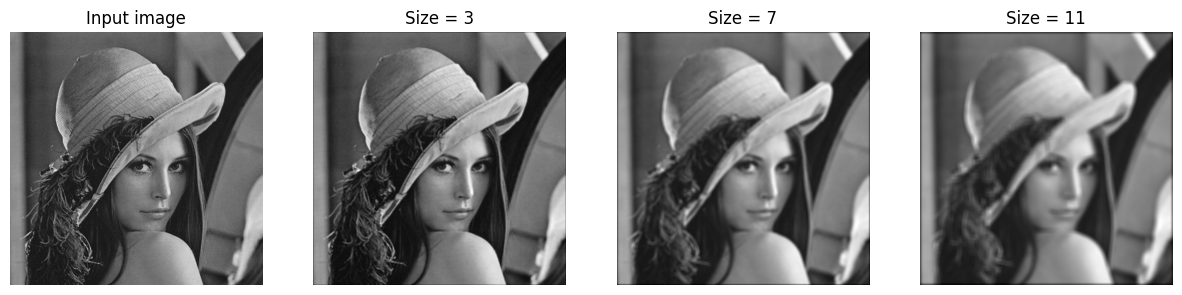

In [21]:
# Apply your box filter to the lena_gs image.
# Use three different sizes for the box filter: 3, 7 and 11.
lena_box3 = conv_2d(lena_gs, box_filter(3))
lena_box7 = conv_2d(lena_gs, box_filter(7))
lena_box11 = conv_2d(lena_gs, box_filter(11))
plt.figure(figsize=(15,10))
plt.subplot(1, 4, 1), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.axis('off'), plt.title('Input image')
plt.subplot(1, 4, 2), plt.imshow(lena_box3, cmap=plt.cm.gray), plt.axis('off'), plt.title('Size = 3')
plt.subplot(1, 4, 3), plt.imshow(lena_box7, cmap=plt.cm.gray), plt.axis('off'), plt.title('Size = 7')
plt.subplot(1, 4, 4), plt.imshow(lena_box11, cmap=plt.cm.gray), plt.axis('off'), plt.title('Size = 11')
plt.show()

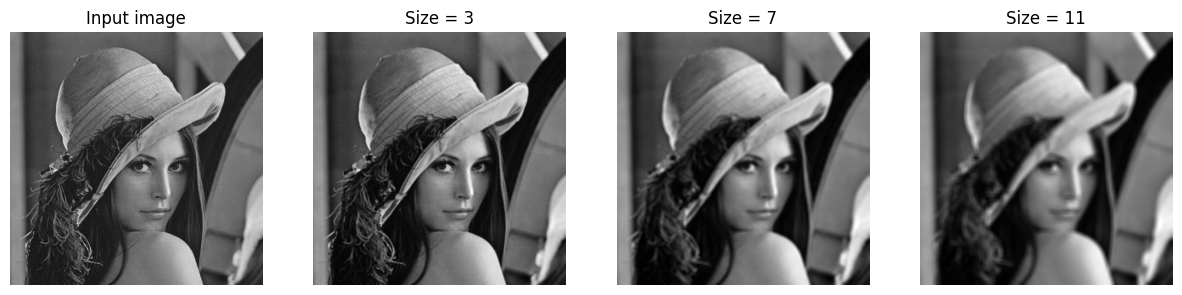

In [22]:
# OpenCV provides a box filter.
# cv2.blur(src, ksize[, dst[, anchor[, borderType]]]) → dst
lena_box3_cv = cv2.blur(np.asarray(lena_gs, dtype=np.float32), (3,3)) #blur(array np src, kernel_size)
lena_box7_cv = cv2.blur(np.asarray(lena_gs, dtype=np.float32), (7,7))
lena_box11_cv = cv2.blur(np.asarray(lena_gs, dtype=np.float32), (11,11))
plt.figure(figsize=(15,10))
plt.subplot(1, 4, 1), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.axis('off'), plt.title('Input image')
plt.subplot(1, 4, 2), plt.imshow(lena_box3_cv, cmap=plt.cm.gray), plt.axis('off'), plt.title('Size = 3')
plt.subplot(1, 4, 3), plt.imshow(lena_box7_cv, cmap=plt.cm.gray), plt.axis('off'), plt.title('Size = 7')
plt.subplot(1, 4, 4), plt.imshow(lena_box11_cv, cmap=plt.cm.gray), plt.axis('off'), plt.title('Size = 11')
plt.show()

In [23]:
# Let's check if the results obtained with NumPy and OpenCV are different.
print("Results checking...")
print("Difference between output images (3x3 kernel): " + str(np.abs(lena_box3 - lena_box3_cv).sum()))
print("Difference between output images (7x7 kernel): " + str(np.abs(lena_box7 - lena_box7_cv).sum()))
print("Difference between output images (11x11 kernel): " + str(np.abs(lena_box11 - lena_box11_cv).sum()))

Results checking...
Difference between output images (3x3 kernel): 72894.77
Difference between output images (7x7 kernel): 187619.77
Difference between output images (11x11 kernel): 298442.8


The results are different. Why? Let's find out..

In [24]:
# Let's remove the borders from the output images
print("Results checking (without borders)...")
noborders_diff_3 = lena_box3[1:-1, 1:-1] - lena_box3_cv[1:-1, 1:-1]
noborders_diff_7 = lena_box7[3:-3, 3:-3] - lena_box7_cv[3:-3, 3:-3]
noborders_diff_11 = lena_box11[5:-5, 5:-5] - lena_box11_cv[5:-5, 5:-5]

print("Difference (3 x 3 kernel): " + str(np.abs(noborders_diff_3).sum()))
print("Difference (7 x 7 kernel): " + str(np.abs(noborders_diff_7).sum()))
print("Difference (11 x 11 kernel): " + str(np.abs(noborders_diff_11).sum()))

Results checking (without borders)...
Difference (3 x 3 kernel): 0.0
Difference (7 x 7 kernel): 0.0
Difference (11 x 11 kernel): 0.0


The cv2.blur function does not use zero-padding!

# **Ex. 3 - 2-D Gaussian Filter**

In this exercise, you will implement with Numpy a kxk Gaussian filter defined by the following equation:

\begin{equation}
G(x, y) = \frac{1}{\sqrt{2 \pi \sigma^2}}{e^{-\frac{x^2+y^2}{2\sigma^2}}}
\end{equation}

Tips: Consider as kernel size an odd number - Use the meshgrid function.

In [25]:
"""
le filtre gaussien 2D. Il ressemble au filtre moyen (box_filter) qu’on vient de voir, mais il attribue davantage d’importance
aux pixels proches du centre du filtre.

le centre du kernel reçoit les poids les plus élevés ; plus on s’éloigne du centre, plus les poids diminuent.

Contrairement au filtre moyen, où tous les coefficients sont identiques, les coefficients du filtre gaussien varient selon la distance au centre.

Le kernel gaussien est généralement normalisé : la somme de tous ses coefficients vaut \(1\). Ainsi, appliquer le filtre revient à calculer une 
moyenne pondérée des pixels voisins.

size = nombre de lignes et de colonnes de la matrice. Plus size est grand, plus le kernel peut couvrir une grande zone autour du pixel central.
sigma = détermine à quelle vitesse les poids diminuent quand on s’éloigne du centre.
        --> Petit sigma : les voisins éloignés ont très peu d’influence. Le flou est généralement plus léger.
        --> Grand sigma : davantage de voisins éloignés contribuent au résultat. Le flou est généralement plus important.
"""

def gaussian_2d(size=11, sigma=1):
    """
    2-D Gaussian Filter

    Input Parameters
    ----------------
    size: int
      Size of the squared kernel
    sigma: float
      Standard deviation

    Output Parameter
    ----------------
    filter: np.array
      2-D Gaussian Filter
    """

    # check input parameters
    assert size % 2 == 1 & size > 0, "size should be an integer positive odd"
    assert sigma > 0, "sigma should be positive"

    # create the grid
    max_possible = size // 2 #MAX
    min_possible = -max_possible #MIN

    size_range = np.arange(min_possible,max_possible+1) #créer la suite min,...,max
    
    x,y = np.meshgrid(size_range,size_range)

    # fill the grid with the gaussian values

    gaussian = np.exp(-(x**2+y**2)/ (2 * (sigma**2))) #formule de l'exposant
    gaussian = gaussian / gaussian.sum() #normaliser le kernel

    return gaussian

gaussian_2d(11,1)

<>:9: SyntaxWarning: invalid escape sequence '\('
<>:9: SyntaxWarning: invalid escape sequence '\('
/var/folders/_g/_pf7z99n3d5b6dc69k3t8rj40000gn/T/ipykernel_3524/3757814237.py:9: SyntaxWarning: invalid escape sequence '\('
  Le kernel gaussien est généralement normalisé : la somme de tous ses coefficients vaut \(1\). Ainsi, appliquer le filtre revient à calculer une


array([[2.21033495e-12, 1.98968011e-10, 6.58891561e-09, 8.02694246e-08,
        3.59742603e-07, 5.93115282e-07, 3.59742603e-07, 8.02694246e-08,
        6.58891561e-09, 1.98968011e-10, 2.21033495e-12],
       [1.98968011e-10, 1.79105296e-08, 5.93115282e-07, 7.22562334e-06,
        3.23829971e-05, 5.33905362e-05, 3.23829971e-05, 7.22562334e-06,
        5.93115282e-07, 1.79105296e-08, 1.98968011e-10],
       [6.58891561e-09, 5.93115282e-07, 1.96412806e-05, 2.39279782e-04,
        1.07237759e-03, 1.76805174e-03, 1.07237759e-03, 2.39279782e-04,
        1.96412806e-05, 5.93115282e-07, 6.58891561e-09],
       [8.02694246e-08, 7.22562334e-06, 2.39279782e-04, 2.91502450e-03,
        1.30642335e-02, 2.15392796e-02, 1.30642335e-02, 2.91502450e-03,
        2.39279782e-04, 7.22562334e-06, 8.02694246e-08],
       [3.59742603e-07, 3.23829971e-05, 1.07237759e-03, 1.30642335e-02,
        5.85498323e-02, 9.65323539e-02, 5.85498323e-02, 1.30642335e-02,
        1.07237759e-03, 3.23829971e-05, 3.59742603e-

In [26]:
gaussian_2d(size=3, sigma=0.886)*16

array([[1.0569757 , 1.99842154, 1.0569757 ],
       [1.99842154, 3.77841103, 1.99842154],
       [1.0569757 , 1.99842154, 1.0569757 ]])

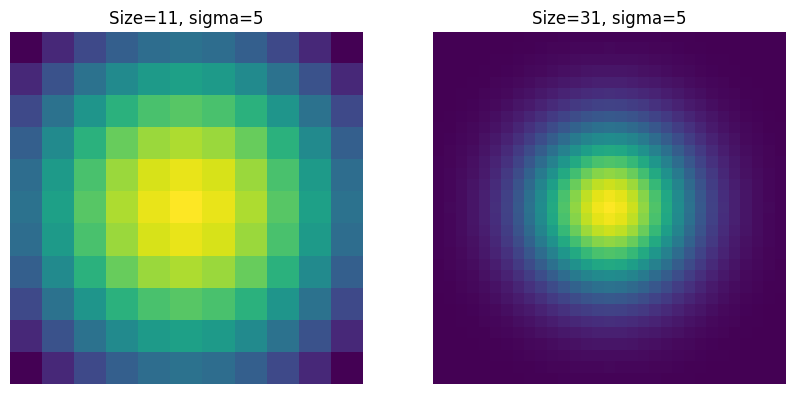

In [27]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(gaussian_2d(size=11, sigma=5)), plt.title('Size=11, sigma=5'), plt.axis('off') #variation de size
plt.subplot(1, 2, 2), plt.imshow(gaussian_2d(size=31, sigma=5)), plt.title('Size=31, sigma=5'), plt.axis('off')
plt.show()

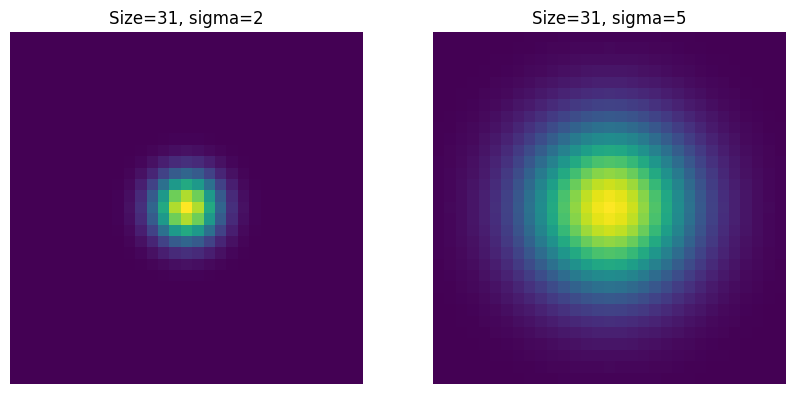

In [28]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(gaussian_2d(size=31, sigma=2)), plt.title('Size=31, sigma=2'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(gaussian_2d(size=31, sigma=5)), plt.title('Size=31, sigma=5'), plt.axis('off')
plt.show()

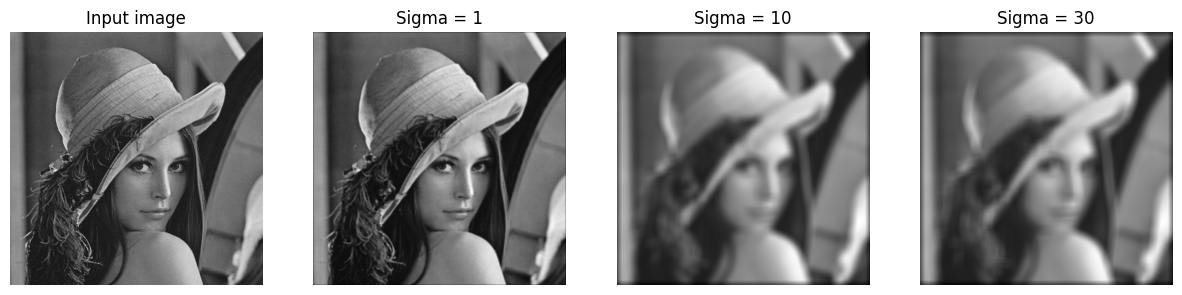

In [29]:
# Apply your box filter to the lena_gs image.
lena_gaussian_1 = conv_2d(lena_gs, gaussian_2d(size=21, sigma=1))
lena_gaussian_10 = conv_2d(lena_gs, gaussian_2d(size=21, sigma=10))
lena_gaussian_30 = conv_2d(lena_gs, gaussian_2d(size=21, sigma=30))
plt.figure(figsize=(15,10))
plt.subplot(1, 4, 1), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.axis('off'), plt.title('Input image')
plt.subplot(1, 4, 2), plt.imshow(lena_gaussian_1, cmap=plt.cm.gray), plt.axis('off'), plt.title('Sigma = 1')
plt.subplot(1, 4, 3), plt.imshow(lena_gaussian_10, cmap=plt.cm.gray), plt.axis('off'), plt.title('Sigma = 10')
plt.subplot(1, 4, 4), plt.imshow(lena_gaussian_30, cmap=plt.cm.gray), plt.axis('off'), plt.title('Sigma = 30')
plt.show()

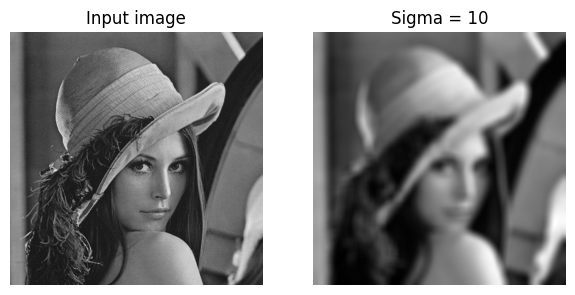

In [30]:
# OpenCV provides the cv2.gaussianblur() function to apply a Gaussian Smoothing to the input image
# dst = cv2.GaussianBlur(src, ksize, sigmaX[, dst[, sigmaY[, borderType=BORDER_DEFAULT]]] )
dst = cv2.GaussianBlur(lena_gs, (21,21), 10)
plt.figure(figsize=(15,10))
plt.subplot(1, 4, 1), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.axis('off'), plt.title('Input image')
plt.subplot(1, 4, 2), plt.imshow(dst, cmap=plt.cm.gray), plt.axis('off'), plt.title('Sigma = 10')
plt.show()

# **Noise Removal**

<p align="justify">Image noise is an undesired effect produced by image sensors or external factors which may obscure the information.</p>

**Noise Removal by Linear Filtering**

<p align="justify">Linear filtering can be used to remove certain types of noise. The following example shows how to remove salt and pepper noise from an image using a median filter (box filter can also be used).</p>

<p align="justify">Box filter sets the value of the output pixel to the average of the pixel values in the neighborhood around the corresponding input pixel. Using the median filter, the value of the output pixel is defined by the median of the neighborhood pixels, rather than the mean. For this reason, the median filter is less sensitive than the mean filter to extreme values (outliers) and it does not reduce the sharpness of the image.</p>

In [31]:
def salt_pepper_noise(image, ratio, amount):
  '''
    Simulate salt&pepper noise for an input grayscale image.

    Le bruit salt and pepper ajoute des pixels très clairs (blancs) et très sombres (noirs) à des endroits aléatoires de l’image.
    ratio = float entre 0 et 1 représentant la part de bruit blanc. Le reste sera en bruit noir (ex:ratio = 0,6 --> 60% blanc & 40%)

    Input Parameters
    ----------------
    image: np.array
      Input image
    ratio: float between 0 and 1
      Salt and pepper noise ratio.
    amount:  float between 0 and 1
      Amount of noise.

    Output parameter
    ----------------
    image: np.array
  '''

  # Check input parameters
  assert len(image.shape) == 2, f"Input image has {image.shape[-1]} channels. \
                                  Grayscale image is required."
  assert 0. <= ratio <= 1., "Ratio parameter must be between 0 and 1."
  assert 0. <= amount <= 1., "Amount parameter must be between 0 and 1."

  # Extract image dimensions
  row, col = image.shape
  output = np.copy(image)

  # Apply salt noise to each pixel individually
  num_salt = np.ceil(amount * image.size * ratio) #np.ceil() arrondit à l'entier supérieur
  coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape] #récupère des coordonnées aléatoires pour les pixels à modifier
  for i in zip(coords[0], coords[1]):
    output[i] = 255 #affecte la valeur blanche maximale

  # Apply pepper noise to each pixel individually
  num_pepper = np.ceil(amount * image.size * (1. - ratio))
  coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
  for i in zip(coords[0], coords[1]):
    output[i] = 0 #affecte la valeur noire minimale

  return output

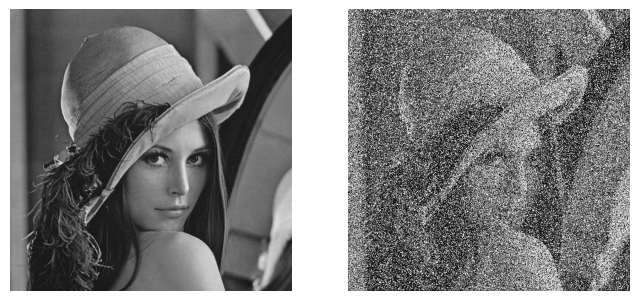

In [32]:
lena_salt_pepper = salt_pepper_noise(lena_gs, 0.6, 0.55)
plt.figure(figsize=(8, 6))
plt.subplot(1, 2, 1), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(lena_salt_pepper, cmap=plt.cm.gray), plt.axis('off')
plt.show()

# **Ex. 4 - Median filter**

<p align="justify">Implement the median filter replacing each pixel of the input image with the median of its neighborhood (use a kxk "patch"). The kernel must be an odd number.

Use a boolean input parameter "padding" to pad (if True) or not (if False) the input image. If padding is True, the input and output image will have the same spatial size.

</p>

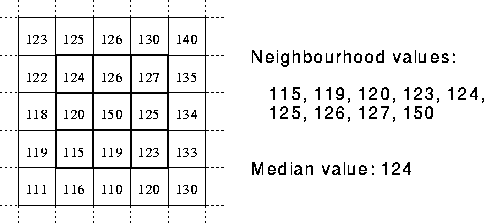

In [33]:
def median_filter(image, kernel_size, padding=True):
    '''
    This function applies the median filter to the input image.

    Input Parameters
    -----------------
    image: np.array
    Input grayscale image
    kernel_size: int
    Dimension of a squared kernel.
    Padding: bool
    If True, the input image is padded with zeros in order to have as output
    an image with the same spatial size of the input image.
    If False, no padded is applied and the output image will be smaller than
    the input one.

    Output Parameters
    ----------------
    image: np.array
    Filtered image

    To check
    ------------
    Grayscale image is required
    kernel size must be an odd number
    '''

    pass

    # check inputs
    assert len(image.shape) == 2, f"Input image has {image.shape[-1]} channels. Grayscale image is required."
    assert kernel_size % 2 == 1, "Kernel size should be odd"
    # code

    if padding is True:
        padding_size = int((kernel_size - 1) / 2) #(k-1)/2
        image_pad = np.pad(image,pad_width=padding_size) #on ajoute du padding à l'image
        output = np.zeros(image.shape, dtype=np.float32) #on crée une image d'output remplie de 0 au départ (même taille image de départ)


        for i in range(output.shape[0]):
            for j in range(output.shape[1]):

                # Extract a kernel_size x kernel_size patch
                patch = image_pad[i:i + kernel_size,
                                  j:j + kernel_size]

                # Replace the pixel by the median of the patch
                output[i, j] = np.median(patch)
    
    else:
        # Calculate the size of the output imag
        output_height = image.shape[0] - kernel_size + 1
        output_width = image.shape[1] - kernel_size + 1

        # Create the smaller output image
        output = np.zeros((output_height, output_width),
                          dtype=np.float32)

        # Go through every valid position
        for i in range(output.shape[0]):
            for j in range(output.shape[1]):

                # Extract a kernel_size x kernel_size patch
                patch = image[i:i + kernel_size,
                              j:j + kernel_size]

                # Store the median
                output[i, j] = np.median(patch)
    
    return output


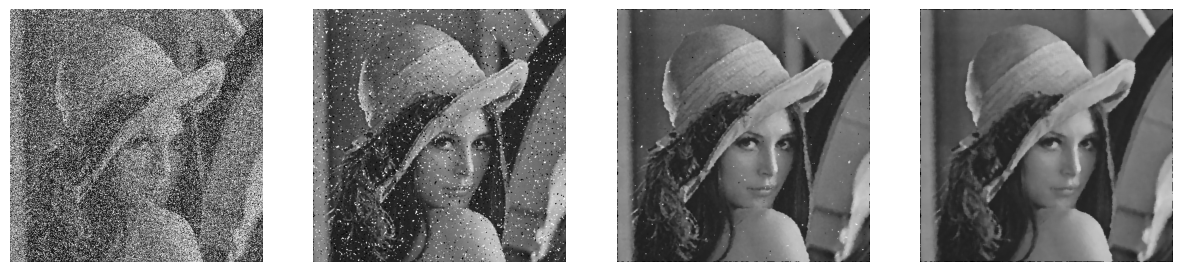

"\nAu plus on augmente le median filter au plus on perd de détails et on lisse l'image et au plus on enlève du bruit ?\n\nKernel plus grand\n        ↓\nVoisinage plus grand analysé\n        ↓\nRéduction du bruit généralement plus forte\n        +\nPlus de lissage / suppression des petits détails\n"

In [34]:
# Apply your median filter to the lena_salt_pepper image.
# Use as kernel size: 3, 5 and 7.
lena_median3 = median_filter(lena_salt_pepper, 3)
lena_median5 = median_filter(lena_salt_pepper, 5)
lena_median7 = median_filter(lena_salt_pepper, 7)
plt.figure(figsize=(15, 12)) #largeur,hauteur
plt.subplot(1, 4, 1), plt.imshow(lena_salt_pepper, cmap=plt.cm.gray), plt.axis('off') #1 ligne, 4 colonnes, position 1
plt.subplot(1, 4, 2), plt.imshow(lena_median3, cmap=plt.cm.gray), plt.axis('off') #1 ligne, 4 colonnes, position 2
plt.subplot(1, 4, 3), plt.imshow(lena_median5, cmap=plt.cm.gray), plt.axis('off') #...
plt.subplot(1, 4, 4), plt.imshow(lena_median7, cmap=plt.cm.gray), plt.axis('off')
plt.show()


"""
Au plus on augmente le median filter au plus on perd de détails et on lisse l'image et au plus on enlève du bruit ?

Kernel plus grand
        ↓
Voisinage plus grand analysé
        ↓
Réduction du bruit généralement plus forte
        +
Plus de lissage / suppression des petits détails
"""

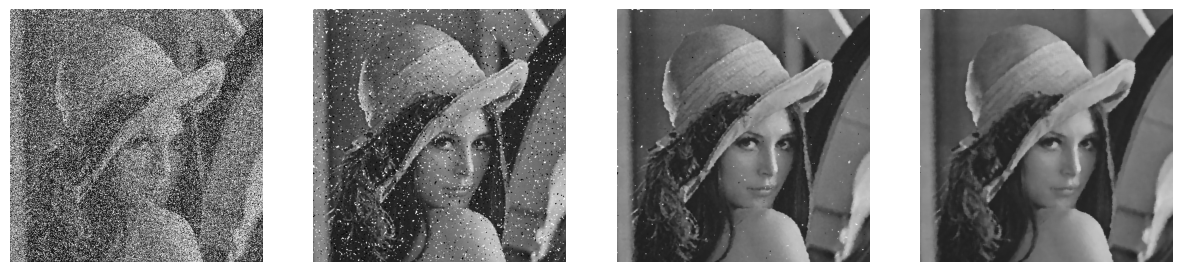

In [35]:
# We will now use the median filter provided by OpenCV.
# cv2.medianBlur(src, ksize[, dst]) → dst
lena_median3_cv = cv2.medianBlur(lena_salt_pepper, 3)
lena_median5_cv = cv2.medianBlur(lena_salt_pepper, 5)
lena_median7_cv = cv2.medianBlur(lena_salt_pepper, 7)
plt.figure(figsize=(15, 12))
plt.subplot(1, 4, 1), plt.imshow(lena_salt_pepper, cmap=plt.cm.gray), plt.axis('off')
plt.subplot(1, 4, 2), plt.imshow(lena_median3_cv, cmap=plt.cm.gray), plt.axis('off')
plt.subplot(1, 4, 3), plt.imshow(lena_median5_cv, cmap=plt.cm.gray), plt.axis('off')
plt.subplot(1, 4, 4), plt.imshow(lena_median7_cv, cmap=plt.cm.gray), plt.axis('off')
plt.show()

In [36]:
print("Results checking...")
print("Difference (3x3 kernel): " + str(np.abs(lena_median3 - lena_median3_cv).sum())) #somme des différences de tout les pixels des 2 images
print("Difference (5x5 kernel): " + str(np.abs(lena_median5 - lena_median5_cv).sum()))
print("Difference (7x7 kernel): " + str(np.abs(lena_median7 - lena_median7_cv).sum()))

"""
erreur vient du padding ajouté avec les 0 artificiels. OpenCV, de son côté, ne gère pas nécessairement 
les bordures exactement comme ton np.pad avec des zéros.

Centre de l'image :
ton résultat = OpenCV ✅

Bordures :
ton résultat ≠ OpenCV ⚠️
"""

Results checking...
Difference (3x3 kernel): 60084.0
Difference (5x5 kernel): 118578.0
Difference (7x7 kernel): 187840.0


"\nerreur vient du padding ajouté avec les 0 artificiels. OpenCV, de son côté, ne gère pas nécessairement \nles bordures exactement comme ton np.pad avec des zéros.\n\nCentre de l'image :\nton résultat = OpenCV ✅\n\nBordures :\nton résultat ≠ OpenCV ⚠️\n"

In [37]:
print("Results checking (without borders)...")
# Remove borders from output images
cropped_diff_3 = lena_median3[1:-1, 1:-1] - lena_median3_cv[1:-1, 1:-1] #si on enlève les bordures
cropped_diff_5 = lena_median5[2:-2, 2:-2] - lena_median5_cv[2:-2, 2:-2]
cropped_diff_7 = lena_median7[3:-3, 3:-3] - lena_median7_cv[3:-3, 3:-3]

print("Difference (3x3 kernel): " + str(np.abs(cropped_diff_3).sum()))
print("Difference (5x5 kernel): " + str(np.abs(cropped_diff_5).sum()))
print("Difference (7x7 kernel): " + str(np.abs(cropped_diff_7).sum()))

Results checking (without borders)...
Difference (3x3 kernel): 0.0
Difference (5x5 kernel): 0.0
Difference (7x7 kernel): 0.0


*   Now, let's use the median_filter function setting to False the padding parameter. The input image will be padded using the cv2.copyMakeBorder function.

In [38]:
# Form a border around an image.
# cv2.copyMakeBorder(src, top, bottom, left, right, borderType[, dst[, value]]) → dst
# Note: The median filter uses cv2.BORDER_REPLICATE internally to cope with border pixels.
lena_salt_pepper_rep_b1 = cv2.copyMakeBorder(lena_salt_pepper, 1, 1, 1, 1, cv2.BORDER_REPLICATE) #permet d'ajouter une bordure à une image
lena_salt_pepper_rep_b2 = cv2.copyMakeBorder(lena_salt_pepper, 2, 2, 2, 2, cv2.BORDER_REPLICATE)
lena_salt_pepper_rep_b3 = cv2.copyMakeBorder(lena_salt_pepper, 3, 3, 3, 3, cv2.BORDER_REPLICATE)
#BORDER_REPLICATE = réplique les valeurs des pixels situés aux bords de l'image.

# Apply median filter function without padding the input image (since it is already padded)
lena_median_rep_borders3 = median_filter(lena_salt_pepper_rep_b1, 3, padding=False)
lena_median_rep_borders5 = median_filter(lena_salt_pepper_rep_b2, 5, padding=False)
lena_median_rep_borders7 = median_filter(lena_salt_pepper_rep_b3, 7, padding=False) #padding = false car on a déjà une bordure

# Let's check the difference between the two results
diff_3 = lena_median_rep_borders3 - lena_median3_cv
diff_5 = lena_median_rep_borders5 - lena_median5_cv
diff_7 = lena_median_rep_borders7 - lena_median7_cv
print("Difference (3x3 kernel): " + str(np.abs(diff_3).sum()))
print("Difference (5x5 kernel): " + str(np.abs(diff_5).sum()))
print("Difference (7x7 kernel): " + str(np.abs(diff_7).sum()))


Difference (3x3 kernel): 0.0
Difference (5x5 kernel): 0.0
Difference (7x7 kernel): 0.0


# **Filter2D function**

OpenCV provides a function for applying an arbitrary linear filter to an image.

*cv2.filter2D* function convolves an image with a kernel ([cv2.filter2D](https://docs.opencv.org/3.4/d4/d86/group__imgproc__filter.html#ga27c049795ce870216ddfb366086b5a04)).

In [39]:
# cv2.filter2D(src, ddepth, kernel[, dst[, anchor[, delta[, borderType]]]]) → dst

# Application of several filter to a gray scale image
# Define the kernel size
kernel_size = 3

# This filter has no effects on the image
kernel_orig = np.zeros((kernel_size,kernel_size))
kernel_orig[1,1] = 1 #centre de la matrice

# Shift all pixels on the right by one pixel
kernel_shift = np.zeros((kernel_size, kernel_size))
kernel_shift[1,2] = 1 #décalement à droite

# Box Filter
kernel_blur = 1/(kernel_size**2) * np.ones((kernel_size,kernel_size)) #1/9

# Horizontal_blur
horizontal_blur = np.zeros((kernel_size,kernel_size)) #1/3 1/3 1/3 sur la ligne du milieu
horizontal_blur[1, :] = 1/kernel_size

# Vertical_blur
vertical_blur = np.zeros((kernel_size,kernel_size)) #1/3 1/3 1/3 sur la colonne du milieu
vertical_blur[:, 1] = 1/kernel_size

# Print kernel filters
print(f"No effect filter:\n{kernel_orig}\n\n")
print(f"Shift filter:\n{kernel_shift}\n\n")
print(f"Blur filter: \n{kernel_blur}\n\n")
print(f"Horizontal blur filter:\n{horizontal_blur}\n\n")
print(f"Vertical blur filter:\n{vertical_blur}\n\n")

No effect filter:
[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]


Shift filter:
[[0. 0. 0.]
 [0. 0. 1.]
 [0. 0. 0.]]


Blur filter: 
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


Horizontal blur filter:
[[0.         0.         0.        ]
 [0.33333333 0.33333333 0.33333333]
 [0.         0.         0.        ]]


Vertical blur filter:
[[0.         0.33333333 0.        ]
 [0.         0.33333333 0.        ]
 [0.         0.33333333 0.        ]]




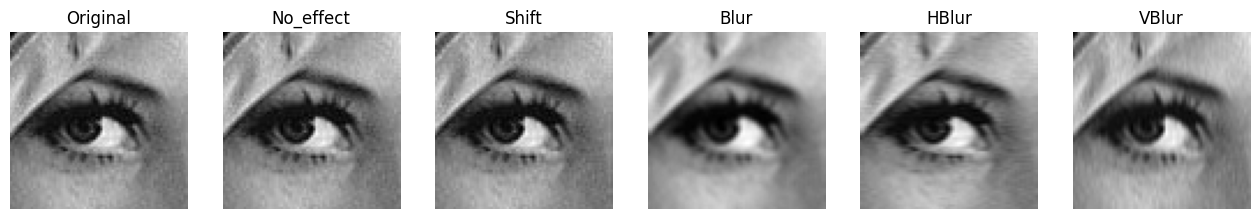

In [40]:
# Apply filters
lena_cropped_gs = cv2.cvtColor(lena_cropped, cv2.COLOR_BGR2GRAY) # GS image

img_orig  = cv2.filter2D(lena_cropped_gs, -1, kernel_orig)
img_shift = cv2.filter2D(lena_cropped_gs, -1, kernel_shift)
img_blur  = cv2.filter2D(lena_cropped_gs, -1, kernel_blur)
img_hblur = cv2.filter2D(lena_cropped_gs, -1, horizontal_blur)
img_vblur = cv2.filter2D(lena_cropped_gs, -1, vertical_blur)

plt.figure(figsize=(16,14))
plt.subplot(1, 6, 1), plt.imshow(lena_cropped_gs, cmap=plt.cm.gray), plt.title('Original'), plt.axis('off')
plt.subplot(1, 6, 2), plt.imshow(img_orig, cmap=plt.cm.gray), plt.title('No_effect'),  plt.axis('off')
plt.subplot(1, 6, 3), plt.imshow(img_shift, cmap=plt.cm.gray), plt.title('Shift'),  plt.axis('off')
plt.subplot(1, 6, 4), plt.imshow(img_blur, cmap=plt.cm.gray), plt.title('Blur'),  plt.axis('off')
plt.subplot(1, 6, 5), plt.imshow(img_hblur, cmap=plt.cm.gray), plt.title('HBlur'),  plt.axis('off')
plt.subplot(1, 6, 6), plt.imshow(img_vblur, cmap=plt.cm.gray), plt.title('VBlur'),  plt.axis('off')
plt.show()

# Ex. 5 - **Sharpening filter**

<p align="justify">While blurring reduces edge contents, sharpening increases them.

A sharpening filter can be obtained in two steps: firstly, a smoothed version of the input image it is subtracted from the input one to obtain the details;  then, the details are added to the original image.</p>

**Step 1**: Original - Smoothed = Details

**Step 2**: Original + k * Details = Sharpened

In this exercise, you will implement a sharpening filter selecting 3 different values for the parameter k (for example, 1, 2 and 3). Use a 21 x 21 filter and the gray scale version of Lena image.

Tips: You can use these two functions -> cv2.GaussianBlur and cv2.addWeighted.

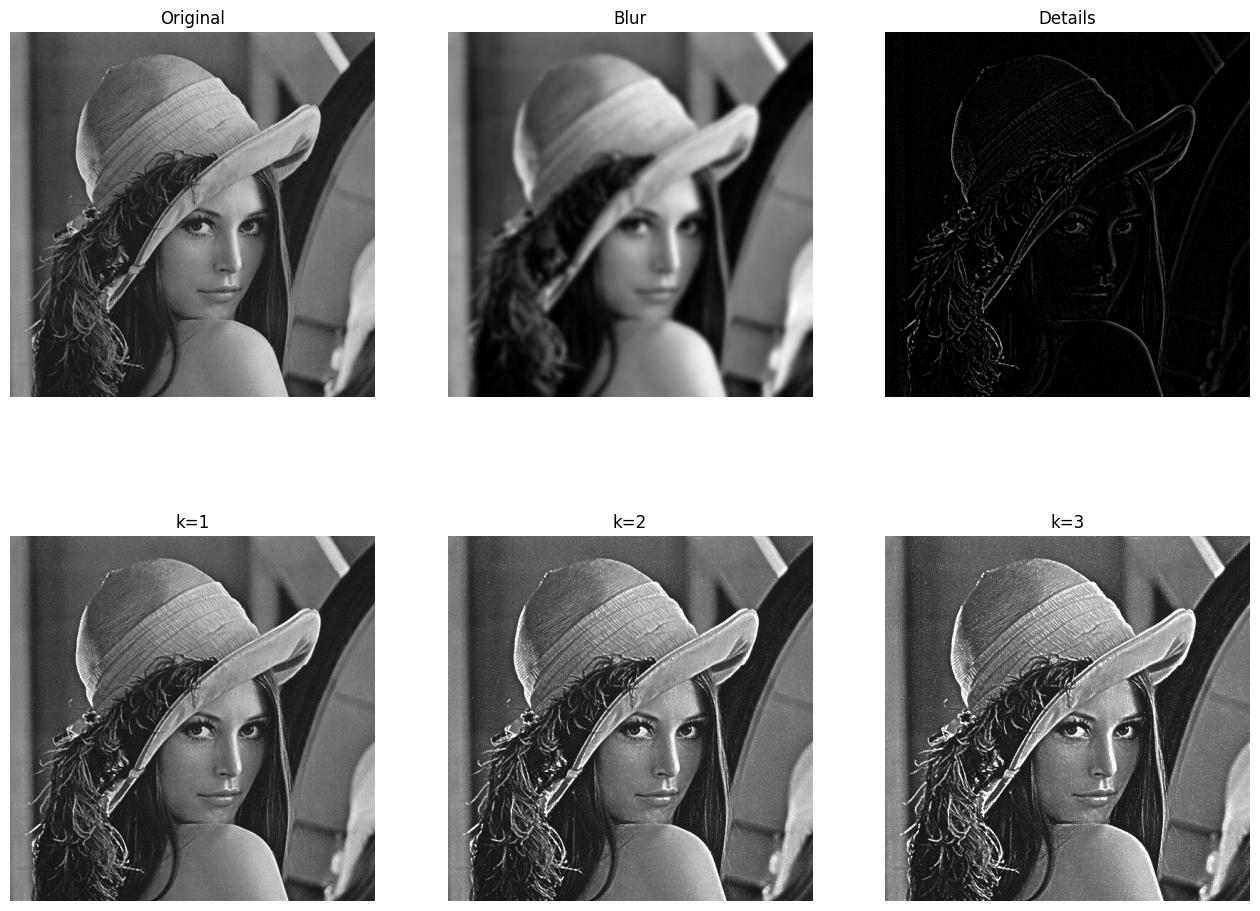

In [41]:
""" YOUR CODE HERE """

# create blurred image
lena_gs_blurred = cv2.GaussianBlur(lena_gs,(21,21),3.0) #kernel size 21x21
lena_gs_details = cv2.addWeighted(lena_gs,1,lena_gs_blurred,-1,0) #result = a * img1 + b * img2 + y (on veut la différence des 2 : a=1 & b=-1)

# cv2.addWeighted is a function that performs addition between two images
# we use it to extract details subtracting the blurred image from the original one (step 1)

# now we use cv2.addWeighted to add the details to the original image (step 2)
k = [1,2,3]
lena_gs_sharpened_1 = cv2.addWeighted(lena_gs,1,lena_gs_details,k[0],0)
lena_gs_sharpened_2 = cv2.addWeighted(lena_gs,1,lena_gs_details,k[1],0)
lena_gs_sharpened_3 = cv2.addWeighted(lena_gs,1,lena_gs_details,k[2],0)

plt.figure(figsize=(16,12))
plt.subplot(2, 3, 1), plt.imshow(lena_gs, cmap=plt.cm.gray), plt.title('Original'), plt.axis('off')
plt.subplot(2, 3, 2), plt.imshow(lena_gs_blurred, cmap=plt.cm.gray), plt.title('Blur'),  plt.axis('off')
plt.subplot(2, 3, 3), plt.imshow(lena_gs_details, cmap=plt.cm.gray), plt.title('Details'),  plt.axis('off')
plt.subplot(2, 3, 4), plt.imshow(lena_gs_sharpened_1, cmap=plt.cm.gray), plt.title('k=1'),  plt.axis('off')
plt.subplot(2, 3, 5), plt.imshow(lena_gs_sharpened_2, cmap=plt.cm.gray), plt.title('k=2'),  plt.axis('off')
plt.subplot(2, 3, 6), plt.imshow(lena_gs_sharpened_3, cmap=plt.cm.gray), plt.title('k=3'),  plt.axis('off')
plt.show()